# AI-Based Student Performance Risk Predictor (ANN)
Multi-class classification (**Low / Medium / High**) with a feed-forward ANN in Keras.
Run the notebook from the `notebooks/` folder (top to bottom).

In [14]:
import sys, json
sys.path.insert(0, '..')                       # so we can import common.py
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from common import *
tf.random.set_seed(SEED); np.random.seed(SEED)
sns.set_theme(style='whitegrid')

## Step 1 - Data understanding

In [15]:
df = load_data(DATA_PATH if DATA_PATH.exists() else '../data/student_data.csv')
display(df.head())
print(json.dumps(data_summary(df), indent=2))
df.describe().T

,student_id,age,attendance_pct,study_hours_per_week,previous_score,assignment_completion_pct,internal_assessment_score,participation_score,sleep_hours_per_day,extracurricular_hours_per_week,failed_subjects,performance_category
0,STU21500,24,73.8,7.9,58.3,100.0,55.6,4.7,4.9,5.0,0,Low
1,STU16476,19,58.1,3.9,61.5,100.0,55.5,8.8,5.3,0.0,1,Low
2,STU23168,18,77.5,24.5,86.2,66.9,69.3,8.3,6.6,7.1,0,High
3,STU10863,17,76.1,17.1,78.8,75.7,62.5,8.4,8.0,7.0,1,High
4,STU15971,22,86.3,4.6,76.2,79.6,72.6,5.5,6.4,2.0,0,Low


{
  "rows": 15000,
  "columns": [
    "student_id",
    "age",
    "attendance_pct",
    "study_hours_per_week",
    "previous_score",
    "assignment_completion_pct",
    "internal_assessment_score",
    "participation_score",
    "sleep_hours_per_day",
    "extracurricular_hours_per_week",
    "failed_subjects",
    "performance_category"
  ],
  "dtypes": {
    "student_id": "str",
    "age": "int64",
    "attendance_pct": "float64",
    "study_hours_per_week": "float64",
    "previous_score": "float64",
    "assignment_completion_pct": "float64",
    "internal_assessment_score": "float64",
    "participation_score": "float64",
    "sleep_hours_per_day": "float64",
    "extracurricular_hours_per_week": "float64",
    "failed_subjects": "int64",
    "performance_category": "str"
  },
  "missing_values": 0,
  "duplicate_rows": 0,
  "duplicate_student_ids": 0,
  "class_distribution": {
    "Medium": 5100,
    "Low": 4950,
    "High": 4950
  }
}


,count,mean,std,min,25%,50%,75%,max
age,15000.0,20.472867,2.281698,17.0,18.0,20.0,22.0,24.0
attendance_pct,15000.0,77.937073,11.672369,45.0,70.0,77.9,86.1,100.0
study_hours_per_week,15000.0,15.171793,6.842051,2.0,10.3,15.1,19.8,40.0
previous_score,15000.0,66.654120,14.744212,25.0,56.8,66.6,76.6,100.0
assignment_completion_pct,15000.0,75.347993,15.885809,20.0,64.4,75.9,87.5,100.0
internal_assessment_score,15000.0,64.825980,15.849283,20.0,54.1,64.7,75.8,100.0
participation_score,15000.0,6.151027,1.950498,1.0,4.8,6.2,7.5,10.0
sleep_hours_per_day,15000.0,6.793887,1.095108,4.0,6.1,6.8,7.5,10.0
extracurricular_hours_per_week,15000.0,5.119900,3.289273,0.0,2.6,5.0,7.4,18.0
failed_subjects,15000.0,0.798133,0.896941,0.0,0.0,1.0,1.0,5.0


**Input features (10):** age, attendance_pct, study_hours_per_week, previous_score, assignment_completion_pct, internal_assessment_score, participation_score, sleep_hours_per_day, extracurricular_hours_per_week, failed_subjects  (`student_id` is only an identifier and is dropped).
**Target:** `performance_category` (Low / Medium / High). Classes are balanced, there are no missing values and no duplicates.

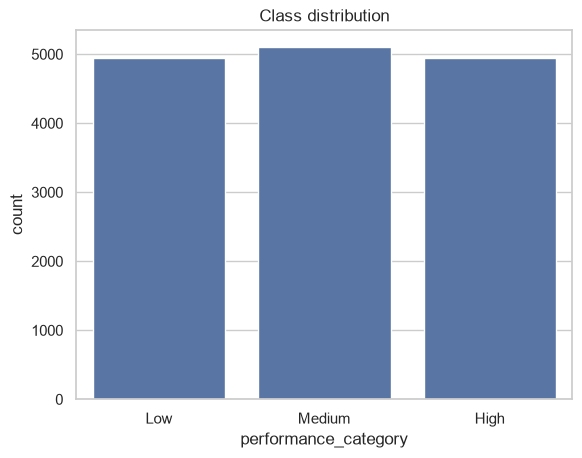

performance_category             High    Low  Medium
age                             20.48  20.52   20.42
attendance_pct                  79.87  75.83   78.11
study_hours_per_week            20.24  10.22   15.06
previous_score                  70.81  62.61   66.54
assignment_completion_pct       78.34  72.36   75.35
internal_assessment_score       68.62  61.26   64.61
participation_score              6.69   5.59    6.17
sleep_hours_per_day              6.91   6.67    6.80
extracurricular_hours_per_week   4.77   5.41    5.18
failed_subjects                  0.62   1.00    0.77


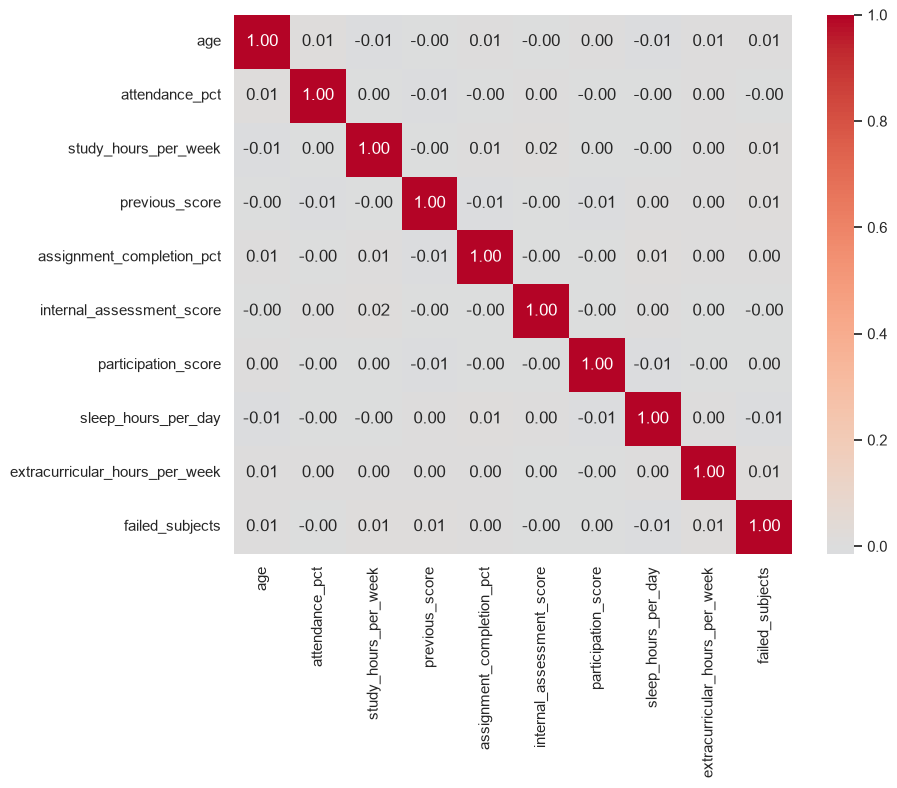

In [16]:
sns.countplot(data=df, x=TARGET, order=CLASSES); plt.title('Class distribution'); plt.show()
print(df.groupby(TARGET)[FEATURES].mean().T.round(2))
plt.figure(figsize=(9,7)); sns.heatmap(df[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.show()

## Step 2 - Preprocessing
* Labels are encoded Low=0, Medium=1, High=2.
* Stratified split: 70 % train / 15 % validation / 15 % test.
* `StandardScaler` is fitted on the **training** split only. Scaling matters for neural networks because features with large ranges (e.g. scores 0-100) would otherwise dominate small ones (e.g. failed subjects 0-5), making gradient descent slow and unstable.

In [17]:
d = prepare_data(df)
X_train, X_val, X_test = d['X_train'], d['X_val'], d['X_test']
y_train, y_val, y_test = d['y_train'], d['y_val'], d['y_test']
print(X_train.shape, X_val.shape, X_test.shape)

(10500, 10) (2250, 10) (2250, 10)


## Step 3 - Baseline: Logistic Regression

In [18]:
base = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train, y_train)
base_pred = base.predict(X_test)
base_res = evaluate(y_test, base_pred)
print(classification_report(y_test, base_pred, target_names=CLASSES))

              precision    recall  f1-score   support

         Low       0.75      0.79      0.77       743
      Medium       0.58      0.57      0.58       765
        High       0.79      0.76      0.77       742

    accuracy                           0.71      2250
   macro avg       0.71      0.71      0.71      2250
weighted avg       0.71      0.71      0.71      2250



## Step 4 - ANN design
`Input(10) -> Dense(32, ReLU) -> Dropout(0.2) -> Dense(16, ReLU) -> Dense(3, Softmax)`

*Why this shape?* The data has only 10 tabular features, so a small network is enough; two hidden layers let it learn non-linear interactions (e.g. high study hours *and* low attendance). Dropout (0.2) reduces overfitting. **ReLU** keeps gradients healthy and is cheap; **Softmax** turns the 3 outputs into probabilities that sum to 1.

In [19]:
model = keras.Sequential([
    layers.Input(shape=(len(FEATURES),)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(3, activation='softmax'),
], name='student_performance_ann')
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "student_performance_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ dense_3 (Dense)               │ (None, 32)            │          352 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout_1 (Dropout)           │ (None, 32)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_4 (Dense)               │ (None, 16)            │          528 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_5 (Dense)               │ (None, 3)             │           51 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 931 (3.64 KB)

 Trainable params: 931 (3.64 KB)

 Non-trainable params: 0 (0.00 B)

## Step 5 - Training
* **Loss:** sparse categorical cross-entropy - measures how far the predicted probabilities are from the true class (labels are integers).
* **Optimizer:** Adam - gradient descent with adaptive per-weight learning rates.
* **Epochs / batch size:** one epoch = one pass over the training data; weights are updated after every batch of 64 samples.
* **Validation data:** not used for weight updates; it tells us when the model starts to overfit (EarlyStopping stops training and restores the best weights).

epochs run: 25


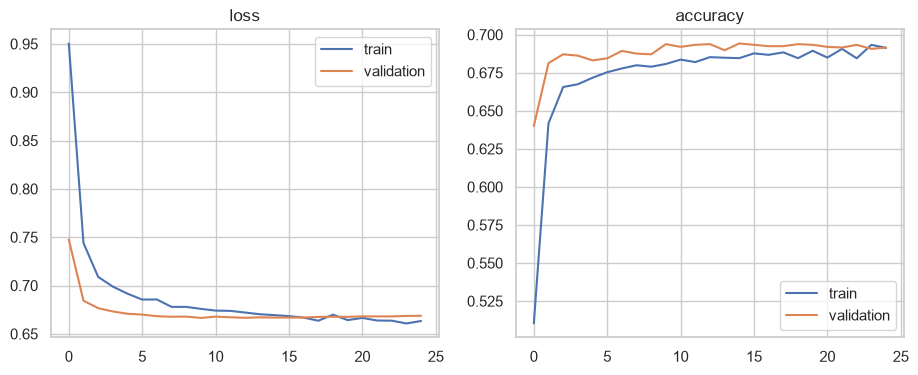

In [20]:
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=150, batch_size=64, verbose=0,
                    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
                               keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6)])
print('epochs run:', len(history.history['loss']))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m in zip(ax, ['loss', 'accuracy']):
    a.plot(history.history[m], label='train'); a.plot(history.history['val_' + m], label='validation'); a.set_title(m); a.legend()
plt.show()

## Step 6 - Neural-network concepts
**Perceptron vs multi-layer ANN.** A perceptron is one neuron: a weighted sum plus bias followed by a step decision, so it can only draw a straight line between classes. A multi-layer ANN stacks layers of neurons with non-linear activations, so it can learn curved, interacting decision boundaries.

**Neuron, weights, bias.** Each neuron computes `z = w1*x1 + ... + wn*xn + b` and outputs `a = activation(z)`. Weights say how important each input is; the bias shifts the decision threshold. Training is the search for good weights and biases.

**Forward propagation.** A scaled student record `x` enters the input layer -> `h1 = ReLU(W1 x + b1)` (32 values) -> `h2 = ReLU(W2 h1 + b2)` (16 values) -> `z = W3 h2 + b3` (3 values) -> `softmax(z)` gives P(Low), P(Medium), P(High). The largest probability is the prediction and also the confidence shown in the app.

**Backpropagation.** The loss compares the probabilities with the true label. Using the chain rule the network computes how much each weight contributed to that error (the gradient), starting at the output layer and moving backwards. The optimizer then nudges every weight a small step against its gradient. Repeating this over many batches and epochs reduces the loss.

## Step 7 - Evaluation on unseen test data

In [21]:
probs = model.predict(X_test, verbose=0)
ann_pred = probs.argmax(axis=1)
ann_res = evaluate(y_test, ann_pred)
print(classification_report(y_test, ann_pred, target_names=CLASSES))
pd.DataFrame({'Logistic Regression': {k: v for k, v in base_res.items() if k in ['accuracy','precision_macro','recall_macro','f1_macro']},
              'ANN': {k: v for k, v in ann_res.items() if k in ['accuracy','precision_macro','recall_macro','f1_macro']}}).round(4)

              precision    recall  f1-score   support

         Low       0.75      0.79      0.77       743
      Medium       0.58      0.56      0.57       765
        High       0.79      0.77      0.78       742

    accuracy                           0.71      2250
   macro avg       0.71      0.71      0.71      2250
weighted avg       0.71      0.71      0.71      2250



,Logistic Regression,ANN
accuracy,0.7067,0.7071
precision_macro,0.7076,0.7069
recall_macro,0.7080,0.7086
f1_macro,0.7075,0.7074


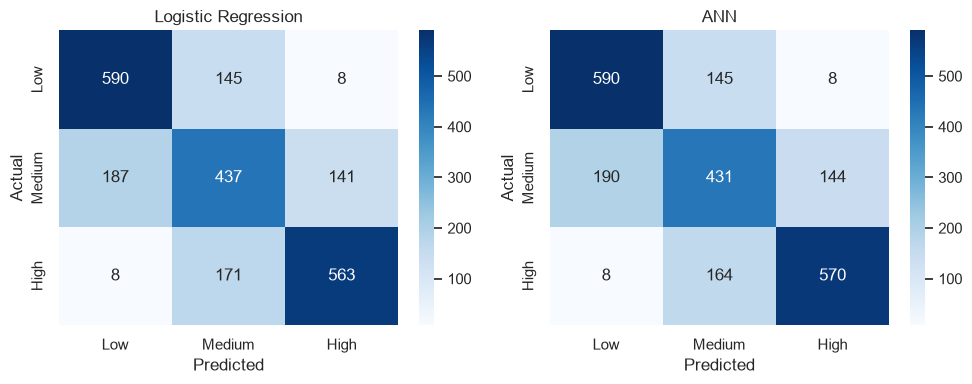

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, res, t in zip(ax, [base_res, ann_res], ['Logistic Regression', 'ANN']):
    sns.heatmap(res['confusion_matrix'], annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=a)
    a.set_title(t); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

**Observations.** Compare the two tables above: if the ANN and the baseline score close to each other, the relationship between features and category is mostly linear for this dataset. The *Medium* class is typically the hardest because it sits between *Low* and *High*.

## Step 8 - Save the model

In [23]:
import joblib
MODEL_DIR.mkdir(exist_ok=True)
model.save(MODEL_PATH)
joblib.dump(d['scaler'], SCALER_PATH)
print('saved to', MODEL_PATH)

saved to C:\Users\shrir\Downloads\student-performance-ann\student-performance-ann\models\student_performance.keras


## Steps 9-10 - Inference
The saved model is loaded without retraining. The same code is used by `app.py` (web UI) and `api.py` (JSON API).

In [24]:
from predictor import Predictor
p = Predictor.from_disk()
sample = {'age': 20, 'attendance_pct': 82, 'study_hours_per_week': 22, 'previous_score': 71,
          'assignment_completion_pct': 80, 'internal_assessment_score': 68, 'participation_score': 7,
          'sleep_hours_per_day': 7, 'extracurricular_hours_per_week': 4, 'failed_subjects': 0}
p.predict(sample)

C:\Users\shrir\Downloads\student-performance-ann\student-performance-ann\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


{'predicted_performance': 'High',
 'confidence': 0.9023,
 'probabilities': {'Low': 0.0017, 'Medium': 0.0959, 'High': 0.9023}}